In [1]:
from pathlib import Path
import json
import tensorflow as tf
import matplotlib.pyplot as plt

DATA_DIR = Path(r"D:\leafguard-ai\Data\plantvillage dataset\color")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [2]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

total_temp_batches = tf.data.experimental.cardinality(temp_ds).numpy()

val_ds = temp_ds.take(total_temp_batches // 2)
test_ds = temp_ds.skip(total_temp_batches // 2)

print("Classes:", len(class_names))
print("Class names:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 54305 files belonging to 38 classes.
Using 38014 files for training.
Found 54305 files belonging to 38 classes.
Using 16291 files for validation.
Classes: 38
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_

In [3]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [4]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [5]:


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())

TensorFlow: 2.21.0
GPUs: []
Training batches: 1188


In [7]:
train_quick = train_ds.take(20)
val_quick = val_ds.take(5)

quick_history = model.fit(
    train_quick,
    validation_data=val_quick,
    epochs=1
)

D:\leafguard-ai\.venv311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 522ms/step - accuracy: 0.1641 - loss: 3.3994 - val_accuracy: 0.4187 - val_loss: 2.3730


In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=2,
        factor=0.2
    )
]

In [10]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 530s 446ms/step - accuracy: 0.8472 - loss: 0.5400 - val_accuracy: 0.9228 - val_loss: 0.2568 - learning_rate: 0.0010
Epoch 2/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 536s 451ms/step - accuracy: 0.9138 - loss: 0.2722 - val_accuracy: 0.9339 - val_loss: 0.2119 - learning_rate: 0.0010
Epoch 3/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 545s 459ms/step - accuracy: 0.9227 - loss: 0.2364 - val_accuracy: 0.9396 - val_loss: 0.1938 - learning_rate: 0.0010


In [11]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

255/255 ━━━━━━━━━━━━━━━━━━━━ 90s 343ms/step - accuracy: 0.9384 - loss: 0.1940 
Test accuracy: 93.84%
Test loss: 0.1940


In [12]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probabilities, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.95      0.86      0.90        92
                                 Apple___Black_rot       0.97      0.96      0.96        97
                          Apple___Cedar_apple_rust       0.85      0.97      0.91        40
                                   Apple___healthy       0.98      0.99      0.98       246
                               Blueberry___healthy       1.00      0.96      0.98       216
          Cherry_(including_sour)___Powdery_mildew       1.00      0.96      0.98       185
                 Cherry_(including_sour)___healthy       0.96      1.00      0.98       132
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.83      0.81      0.82        86
                       Corn_(maize)___Common_rust_       0.99      1.00      0.99       164
               Corn_(maize)___Northern_Leaf_Blight       0.90      0.90      0.

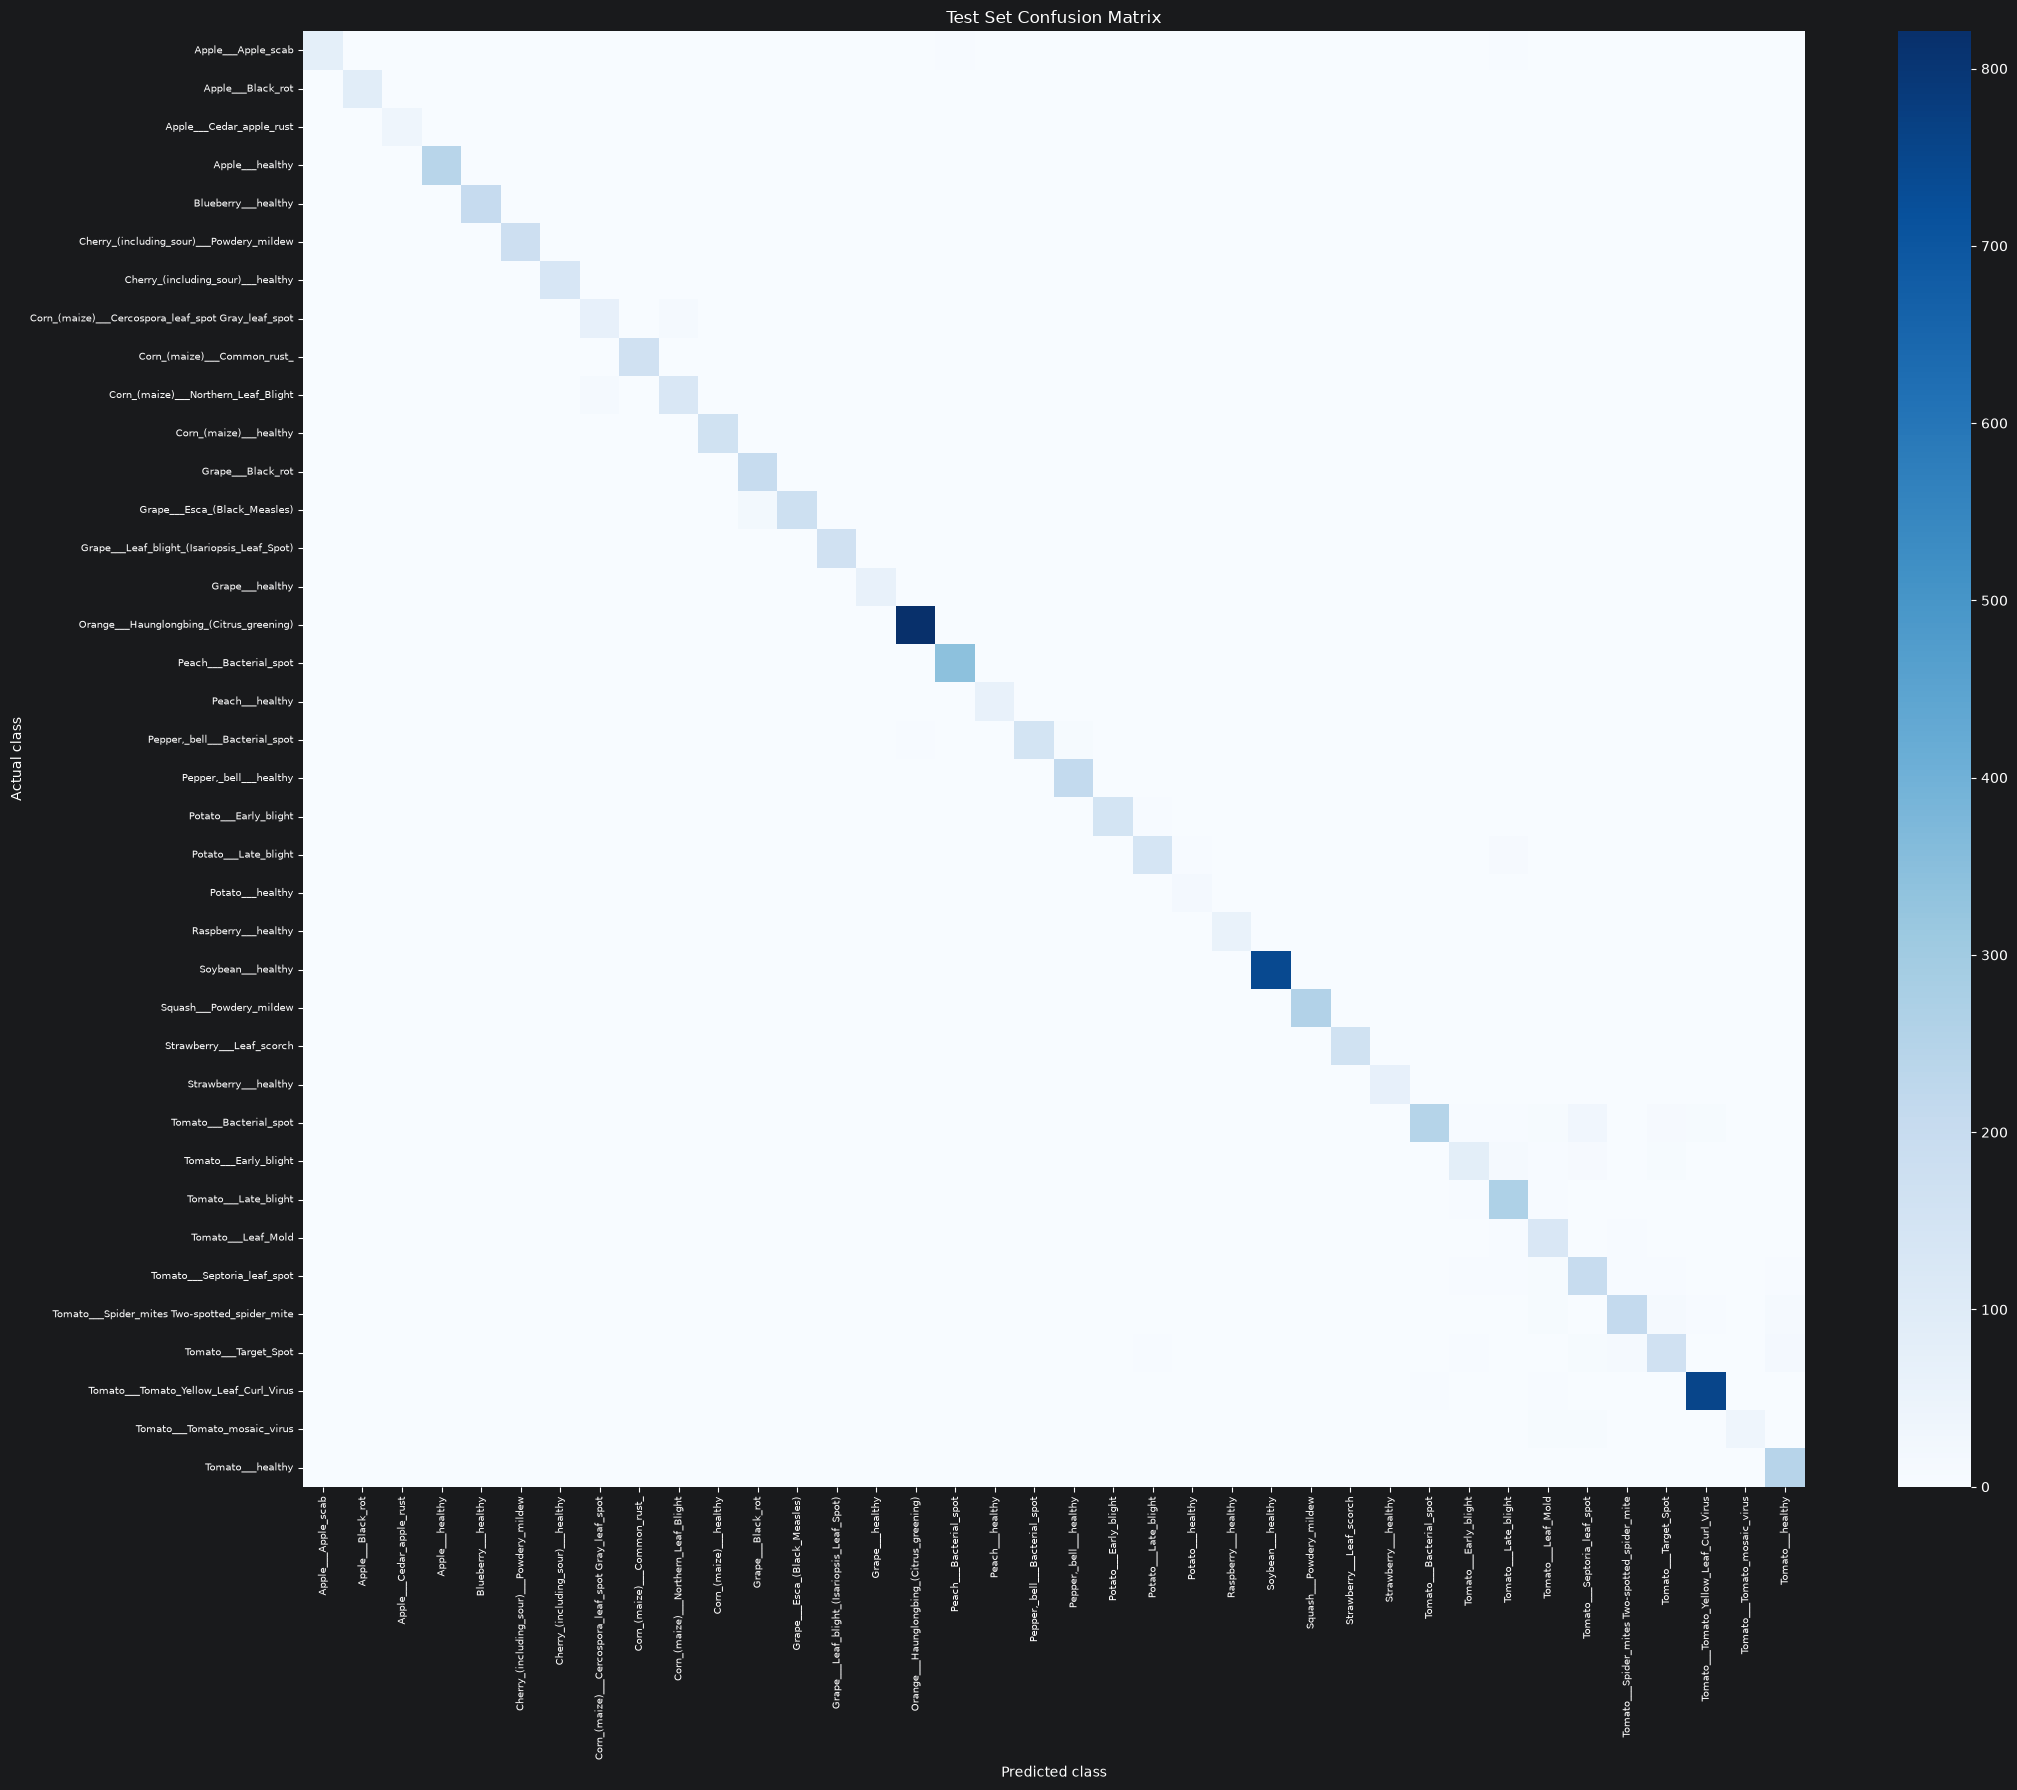

In [13]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(22, 18))
sns.heatmap(
    matrix,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Test Set Confusion Matrix")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

report_dir = Path(r"D:\leafguard-ai\reports")
report_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(report_dir / "confusion_matrix.png", dpi=160)
plt.show()

In [14]:
from pathlib import Path
import json

MODEL_DIR = Path(r"D:\leafguard-ai\Models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model.save(MODEL_DIR / "leafguard_mobilenetv2.keras")

with open(MODEL_DIR / "class_names.json", "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=2)

print("Saved model and class names to:", MODEL_DIR)

Saved model and class names to: D:\leafguard-ai\Models


In [ ]:
  plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss")

plt.tight_layout()
plt.show()